This project is classification of flowers. We will be classififying btween wether the flower is a rose, daisy, dandelion, sunflower or tulips.

Import fastai and find path of flowers

In [2]:
from fastai.vision.all import *

In [3]:
from fastcore.all import *

In [4]:
path = untar_data(URLs.FLOWERS)

<div><progress max="345236087" value="345243648"></progress> 100.00% [345243648/345236087 00:21&lt;00:00]</div>

In [36]:
file_names = get_image_files(path/'jpg' )

Mkaing the dataset smaller from 102 to 5

In [75]:
flower_mapping = {
    74: "rose",
    50: "dandelion",
    39: "tulip",
    54: "sunflower",
    49: "daisy"}


In [105]:
f'We have {len(file_names)} images'

'We have 5 images'

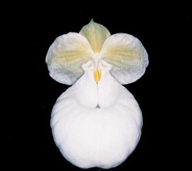

In [103]:
img = PILImage.create(file_names[65])
img.to_thumb(192)


<Axes: >

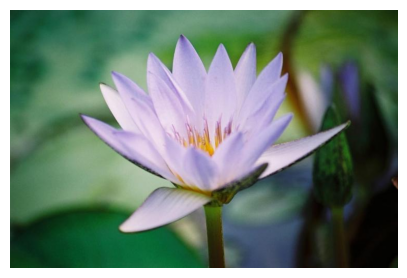

In [102]:
img = PILImage.create(file_names[0])
img.show()

In [9]:
file_names[:5]

[Path('/root/.fastai/data/oxford-102-flowers/jpg/image_00404.jpg'), Path('/root/.fastai/data/oxford-102-flowers/jpg/image_03720.jpg'), Path('/root/.fastai/data/oxford-102-flowers/jpg/image_05570.jpg'), Path('/root/.fastai/data/oxford-102-flowers/jpg/image_01151.jpg'), Path('/root/.fastai/data/oxford-102-flowers/jpg/image_06202.jpg')]

In [108]:
#Uses functions to change flower numbers into flower name and labels them
def get_flower_number(fname):
    image_number = int(fname.stem.split('_')[-1])
    return int(labels[image_number - 1])

def label_function(fname):
    flower_number = get_flower_number(fname)
    return flower_mapping[flower_number]


In [109]:

dblock = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    get_items=get_flower_images,
    get_y=label_function,
    splitter=RandomSplitter(valid_pct=0.2, seed=42),
    item_tfms=Resize(224)
)

dls = dblock.dataloaders(path/"jpg")

print(dls.vocab)
print("Number of classes:", len(dls.vocab))


['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']
Number of classes: 5


In [110]:
len(dls.train_ds), len(dls.valid_ds)

(332, 82)

Looking at the labeling of the flowers

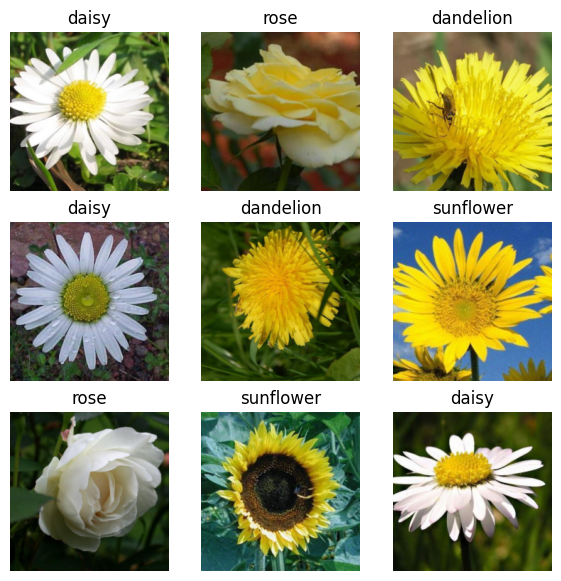

In [111]:
dls.show_batch(max_n=9, figsize=(7,7))

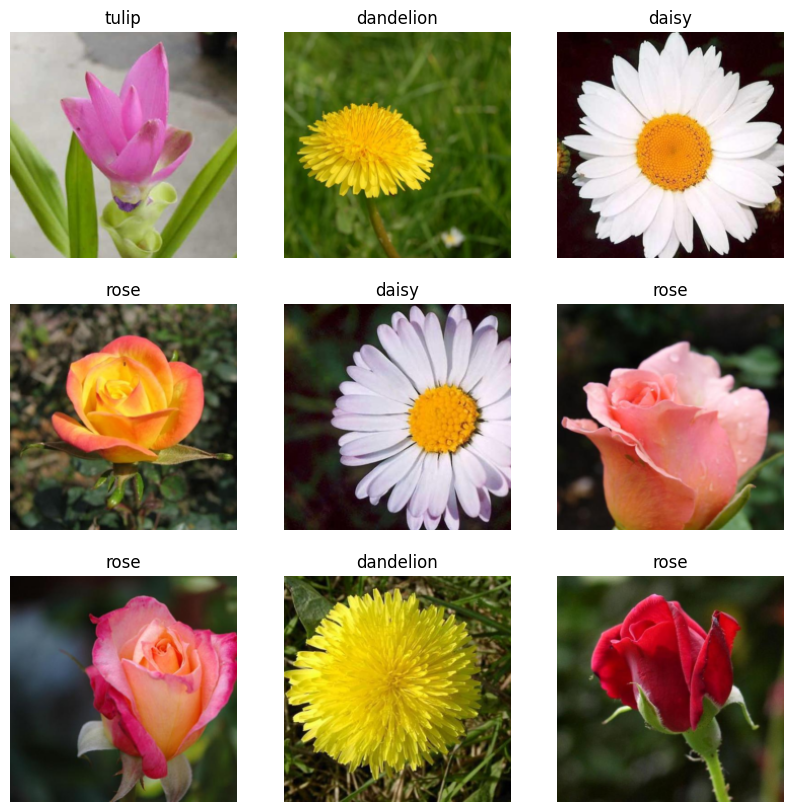

In [113]:
dls.show_batch(max_n=9, figsize=(10, 10))

Training the data

In [82]:
print("Training images:", len(dls.train_ds))
print("Validation images:", len(dls.valid_ds))

Training images: 332
Validation images: 82


In [83]:
learn = vision_learner(dls, resnet18, metrics=accuracy)
learn.fine_tune(5)

epoch,train_loss,valid_loss,accuracy,time
0,1.986464,0.330835,0.865854,01:29


epoch,train_loss,valid_loss,accuracy,time
0,0.289714,0.100658,0.975610,01:51
1,0.192487,0.032502,0.987805,01:55
2,0.130410,0.032042,0.987805,01:52
3,0.094064,0.033691,0.987805,01:55
4,0.073493,0.036220,0.987805,01:52


In [84]:
interp = ClassificationInterpretation.from_learner(learn)

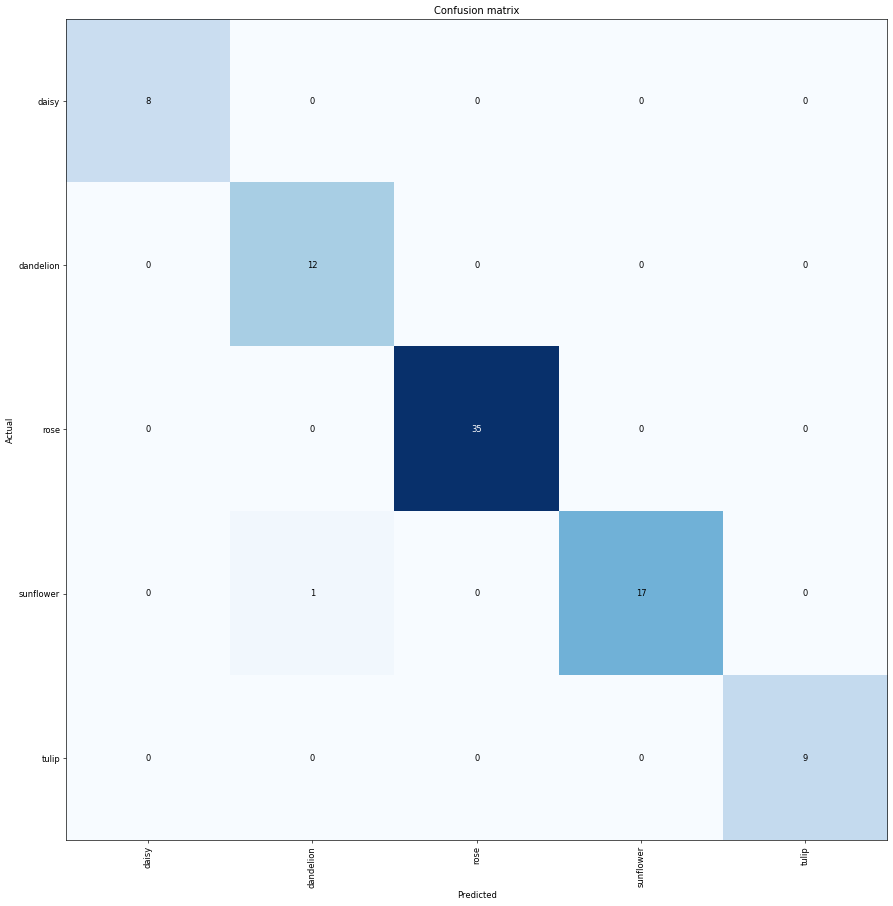

In [85]:
interp.plot_confusion_matrix(figsize=(15, 15), dpi=60)

Testing the accurary and prediction of what flower it is

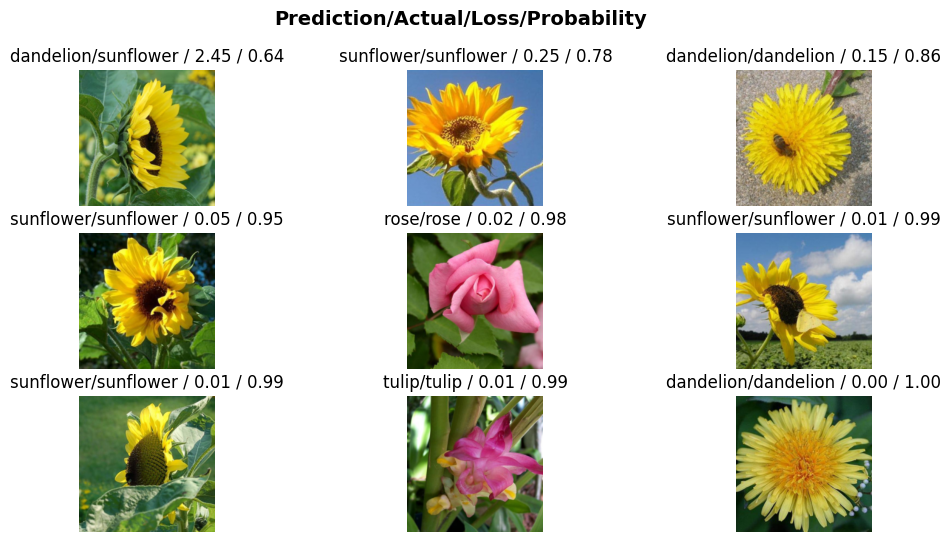

In [89]:
interp.plot_top_losses(9, figsize=(12, 6))

Predicted flower: tulip.
Probability it is this animal is a *flower =  0.005066


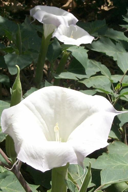

In [90]:
img = PILImage.create(file_names[500])

prediction,_,probs = learn.predict(img)

print(f"Predicted flower: {prediction}.")
print(f"Probability it is this animal is a *flower =  {probs[1].item():.6f}")
img.to_thumb(192)

In [91]:
cm = interp.confusion_matrix()
print(f"Error rate: {(cm.sum() - cm.trace()) / cm.sum():.2%}")

Error rate: 1.22%


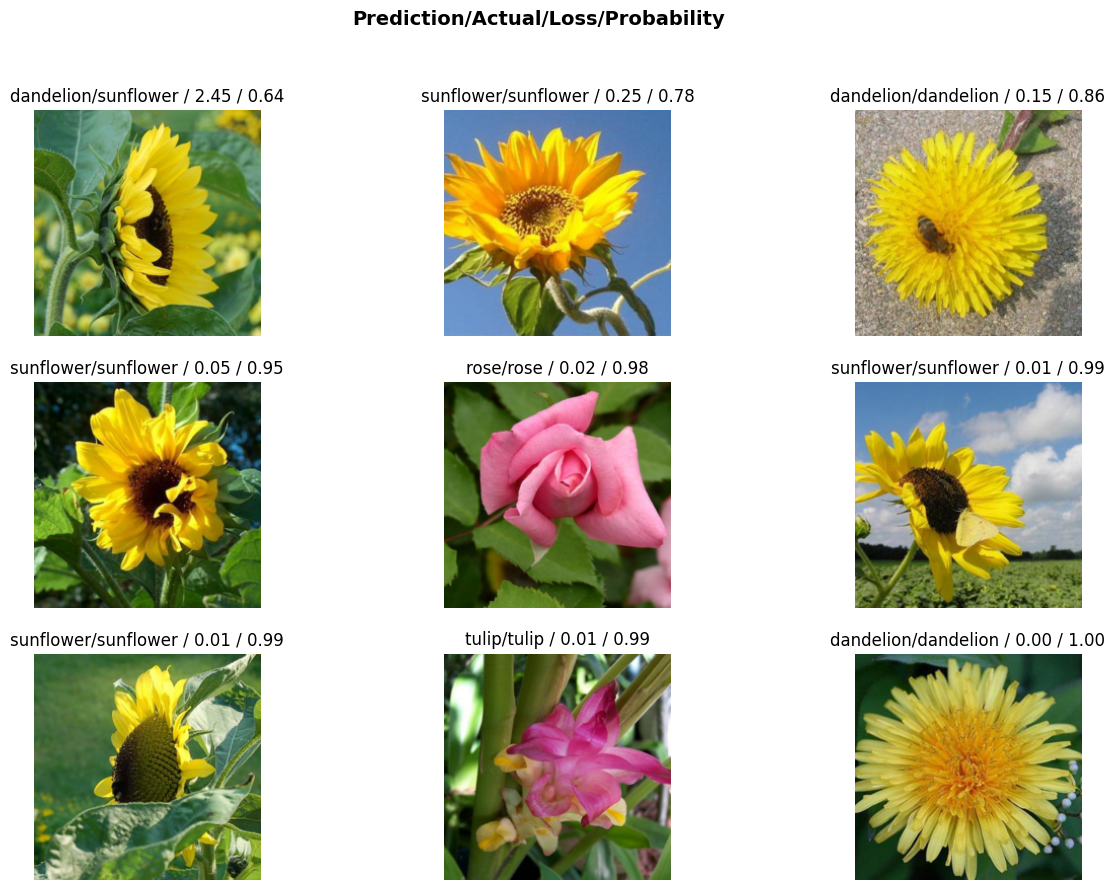

In [92]:
interp.plot_top_losses(9, figsize=(15,10))

Uplod picture from wiki of a tulip to check prediction

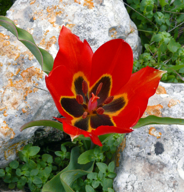

In [118]:

import urllib.request
from fastai.vision.all import *
url = "https://commons.wikimedia.org/wiki/Special:FilePath/Tulip_agenensis_ZE.jpg"
req = urllib.request.Request(
    url,
    headers={'User-Agent': 'Mozilla/5.0'})
try:
    with urllib.request.urlopen(req) as response:
        with open('tulip.jpg', 'wb') as out_file:
            out_file.write(response.read())

    img = PILImage.create('tulip.jpg')

    # Display tulip
    display(img.to_thumb(192))

except Exception as e:
    print(f"Download failed: {e}")

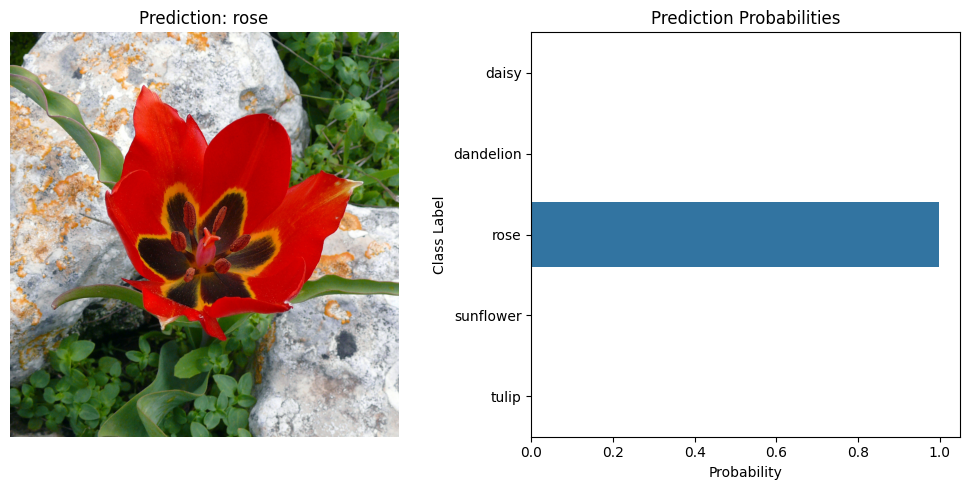

In [119]:
prediction, _, probs = learn.predict(img)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Display the image in the first subplot
axes[0].imshow(img)
axes[0].axis('off')
axes[0].set_title(f"Prediction: {prediction}")

# Display the bar plot in the second subplot
sns.barplot(x=probs, y=dls.vocab, orient='h', ax=axes[1])
axes[1].set_xlabel("Probability")
axes[1].set_ylabel("Class Label")
axes[1].set_title("Prediction Probabilities")

plt.tight_layout()
plt.show()

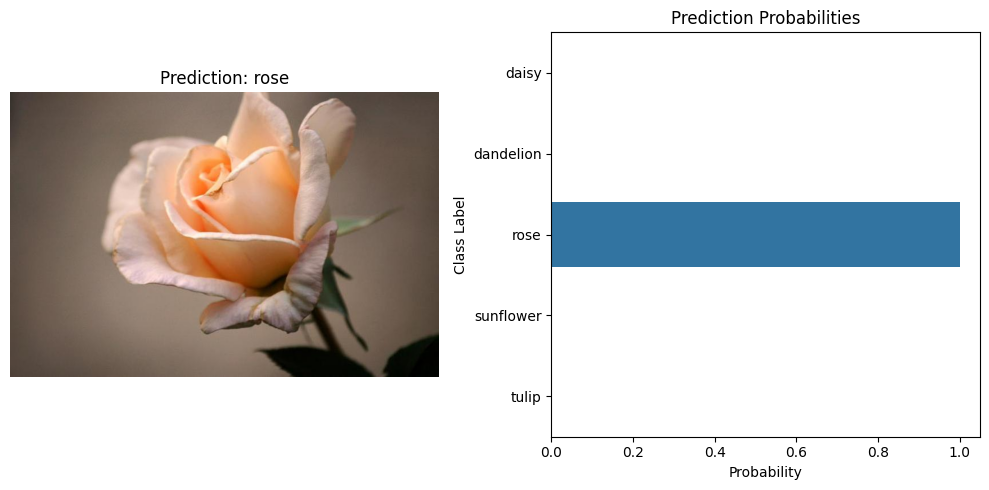

In [120]:
import matplotlib.pyplot as plt
import seaborn as sns

img = PILImage.create(file_names[3])
prediction, _, probs = learn.predict(img)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))  # 1 row, 2 columns

# Display the image in the first subplot
axes[0].imshow(img)
axes[0].axis('off')
axes[0].set_title(f"Prediction: {prediction}")

# Display the bar plot in the second subplot
sns.barplot(x=probs, y=dls.vocab, orient='h', ax=axes[1])
axes[1].set_xlabel("Probability")
axes[1].set_ylabel("Class Label")
axes[1].set_title("Prediction Probabilities")

plt.tight_layout()
plt.show()